In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

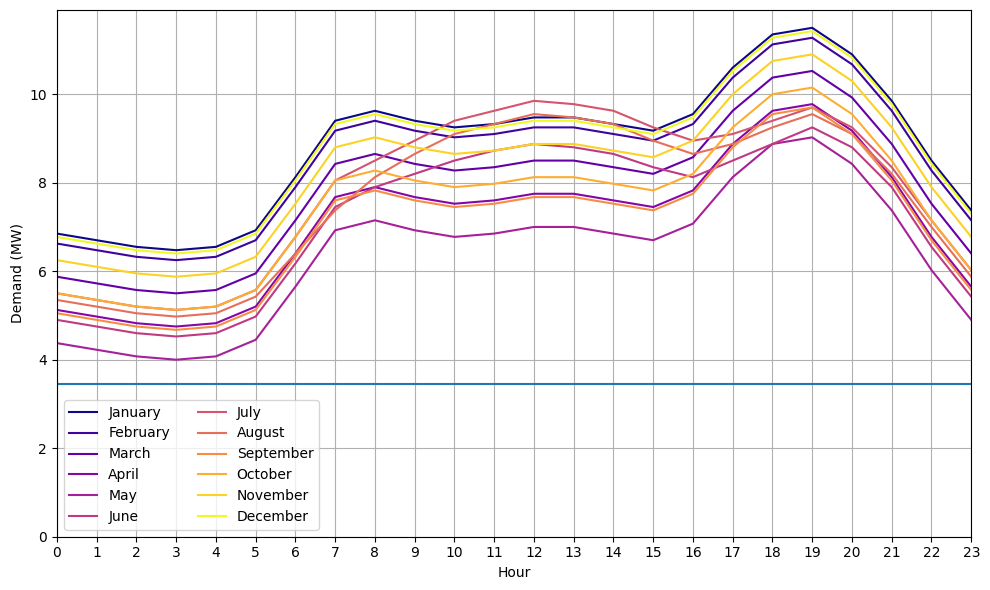

In [3]:
df_load = pd.read_csv("universal_load_288.csv")
P_base = 4e6 # Base Load = 4 MW
P_peak = 11.5e6 # Peak Load = 11.5 MW
df_load["P_demand"] = ( P_base + df_load["Dimensionless_Load"] * (P_peak - P_base)) # P_demand = P_base + M( month, hour) * (P_peak - P_base)

month_names = ["January", "February", "March", "April","May", "June", "July", "August","September", "October", "November", "December"]

plt.figure(figsize=(10, 6))

cmap = plt.colormaps["plasma"]
for month, group in df_load.groupby("Month"):
    plt.plot( group["Hour"], group["P_demand"]*1e-6, color=cmap((month - 1) / 11), label=month_names[month - 1])

thermal_P_min = P_peak*30/100 #from section 4.2
plt.hlines(thermal_P_min*1e-6 , 0 ,23) # Energy demand is always higher than the minimum 30% of load

plt.xlabel("Hour")
plt.ylabel("Demand (MW)")
plt.xticks(range(24))
plt.xlim((0,23))
plt.ylim(bottom=0)
plt.grid(True)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

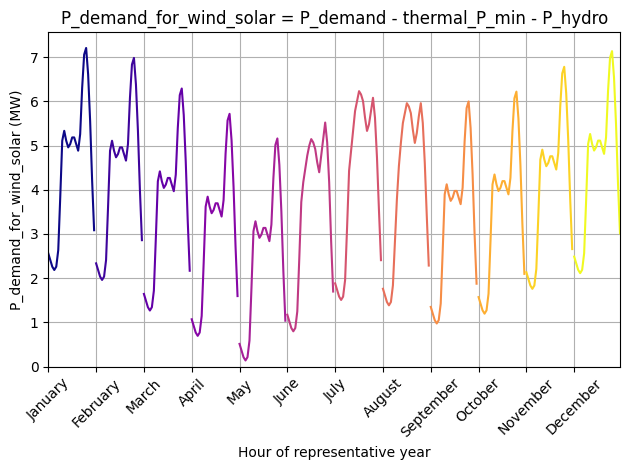

In [4]:
df_hydro = pd.read_csv("hydro_288h.csv")
P_hydro = df_hydro["Power (W)"]
P_demand = df_load["P_demand"]

P_demand_for_wind_solar = P_demand - thermal_P_min - P_hydro
df_load["P_demand_for_wind_solar"] = (df_load["P_demand"] - thermal_P_min - P_hydro)

for month, group in df_load.groupby("Month"):
    plt.plot( (month - 1) * 24 + group["Hour"], group["P_demand_for_wind_solar"]* 1e-6, color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5    )

plt.xlabel("Hour of representative year")
plt.ylabel("P_demand_for_wind_solar (MW)")
plt.title("P_demand_for_wind_solar = P_demand - thermal_P_min - P_hydro")
# Mark the beginning of each representative day
plt.xticks( np.arange(0, 288, 24), month_names, rotation=45 )

plt.xlim(0, 287)
plt.ylim(bottom=0)
plt.grid(True)
#plt.legend(ncol=2)
plt.tight_layout()
plt.show()

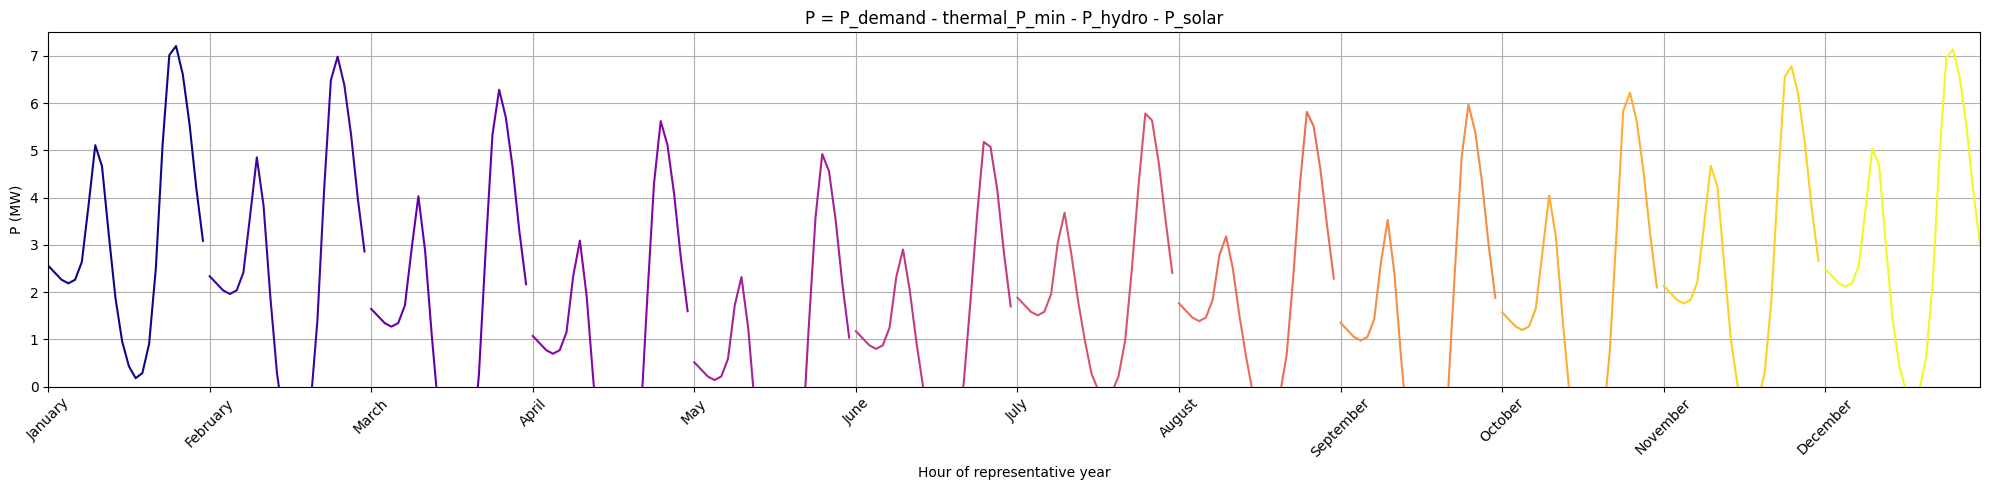

In [5]:
df_solar = pd.read_csv("solar_288h_representative_matrix.csv")
solar_MWp = 8

df_load["P_demand_just_solar_hydro_minThermal"]=df_load["P_demand_for_wind_solar"] - df_solar["P_AC_per_MWp"]*solar_MWp*1e6

plt.figure(figsize=(20, 5))
for month, group in df_load.groupby("Month"):
    plt.plot( (month - 1) * 24 + group["Hour"], group["P_demand_just_solar_hydro_minThermal"]* 1e-6, color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5    )

plt.xlabel("Hour of representative year")
plt.ylabel("P (MW)")
plt.title("P = P_demand - thermal_P_min - P_hydro - P_solar")

plt.xticks( np.arange(0, 288, 24), month_names, rotation=45 )
plt.xlim(0, 287)
plt.ylim(bottom=0, top=7.5)
plt.grid(True)
#plt.legend(ncol=2)
plt.tight_layout()
plt.show()


In [6]:
# for month, group in df_load.groupby("Month"):
#     plt.plot( (month - 1) * 24 + group["Hour"], group["P_demand"] * 1e-6, color=cmap((month - 1) / 11), linewidth=1.5) #, label=month_names[month - 1]
 
# thermal_P_min = P_peak * 30 / 100
# plt.plot(np.arange(0, 288,1), (thermal_P_min+P_hydro) * 1e-6, color="green", linestyle="-", label="Minimum thermal power + Hydro")

# plt.xlabel("Hour of representative year")
# plt.ylabel("Demand (MW)")
# plt.xticks( np.arange(0, 288, 24), month_names, rotation=45)
# plt.xlim(0, 287)
# plt.ylim(bottom=0)
# plt.grid(True)
# plt.tight_layout()
# plt.legend()
# plt.show()

Index(['Month', 'Hour', 'U_hub_ms', 'Wind_pu'], dtype='str')


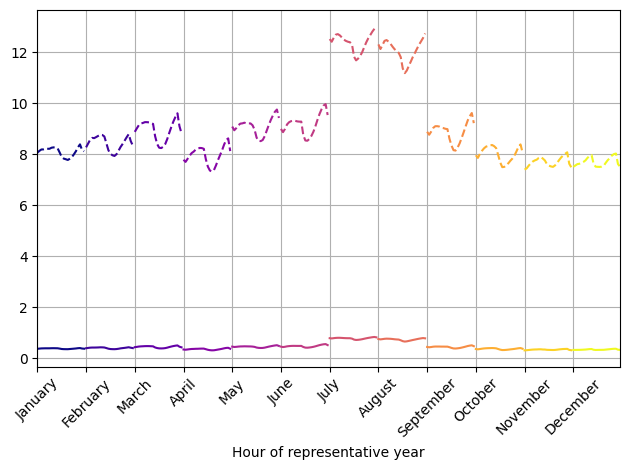

In [7]:
df_wind = pd.read_csv("wind_288_per_MW.csv")
print(df_wind.columns)

for month, group in df_wind.groupby("Month"):
    plt.plot( (month - 1) * 24 + group["Hour"], group["U_hub_ms"], color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5 , linestyle="--"   )
    plt.plot( (month - 1) * 24 + group["Hour"], group["Wind_pu"], color=cmap((month - 1) / 11), label=month_names[month - 1], linewidth=1.5    )

plt.xlabel("Hour of representative year")
# plt.ylabel("P (MW)")
# plt.title("P = P_demand - thermal_P_min - P_hydro - P_solar")
plt.xticks( np.arange(0, 288, 24), month_names, rotation=45 )
plt.xlim(0, 287)
#plt.ylim(bottom=0, top=7.5)
plt.grid(True)
#plt.legend(ncol=2)
plt.tight_layout()
plt.show()

In [20]:
solar_df = pd.read_csv('solar_288h_representative_matrix.csv')
solar_dist = solar_df['P_AC_per_MWp']
wind_df = pd.read_csv('wind_288_per_MW.csv')
wind_dist = wind_df['Wind_pu']

solar_P = 5
wind_P = 4.7

solar_power = solar_dist * solar_P * 1e6
wind_power = wind_dist * wind_P * 1e6

P = solar_power + wind_power + P_hydro + thermal_P_min
P_demand = P_demand



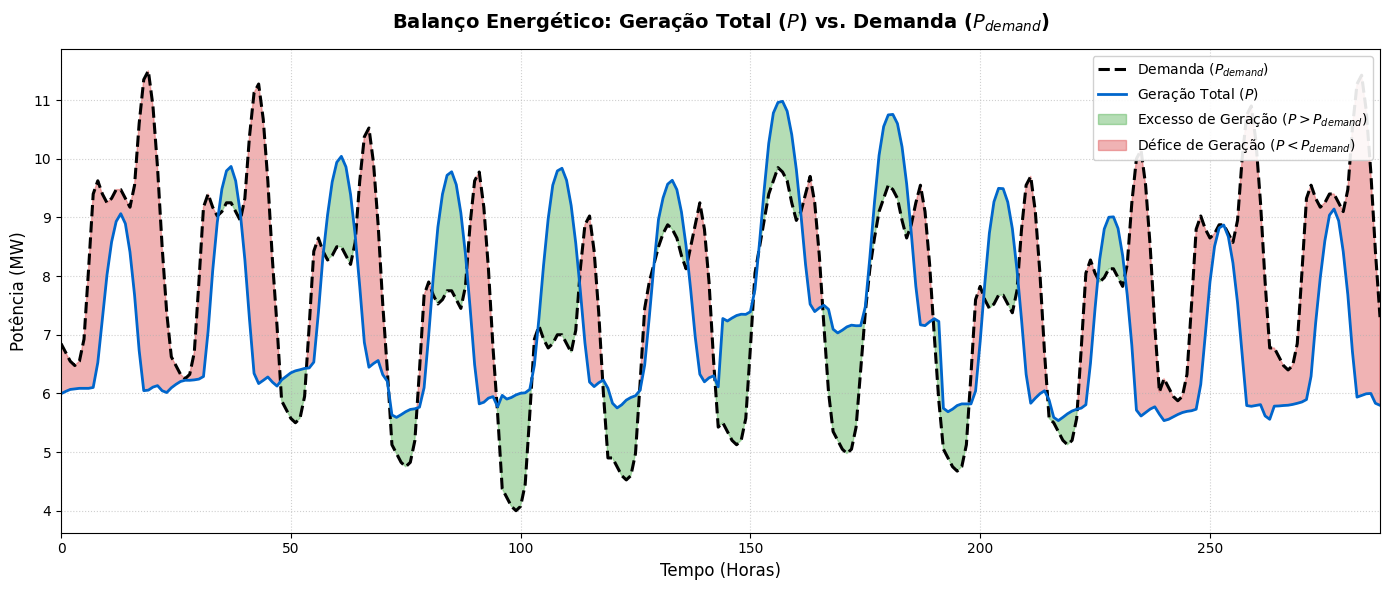

In [23]:

# 1. Ajuste de Unidades (Convertendo Watts para Megawatts para legibilidade)
# Se P e P_demand estiverem em W (devido ao multiplicador 1e6), dividimos por 1e6
P_MW = P / 1e6
P_demand_MW = P_demand / 1e6 

# Eixo temporal (288 horas)
horas = np.arange(len(P_MW))

# 2. Criação da Figura
plt.figure(figsize=(14, 6), dpi=100)

# Curvas Principais
plt.plot(horas, P_demand_MW, label='Demanda ($P_{demand}$)', color='black', linewidth=2.2, linestyle='--')
plt.plot(horas, P_MW, label='Geração Total ($P$)', color='#0066cc', linewidth=2)

# 3. Preenchimento de Excesso vs. Défice
# Área verde: Geração acima da demanda (Sobra de energia / Excesso)
plt.fill_between(horas, P_MW, P_demand_MW, where=(P_MW >= P_demand_MW), 
                 color='#2ca02c', alpha=0.35, interpolate=True, label='Excesso de Geração ($P > P_{demand}$)')

# Área vermelha: Geração abaixo da demanda (Défice a cobrir)
plt.fill_between(horas, P_MW, P_demand_MW, where=(P_MW < P_demand_MW), 
                 color='#d62728', alpha=0.35, interpolate=True, label='Défice de Geração ($P < P_{demand}$)')

# 4. Formatação e Estética
plt.title('Balanço Energético: Geração Total ($P$) vs. Demanda ($P_{demand}$)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tempo (Horas)', fontsize=12)
plt.ylabel('Potência (MW)', fontsize=12)
plt.xlim(0, len(horas) - 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

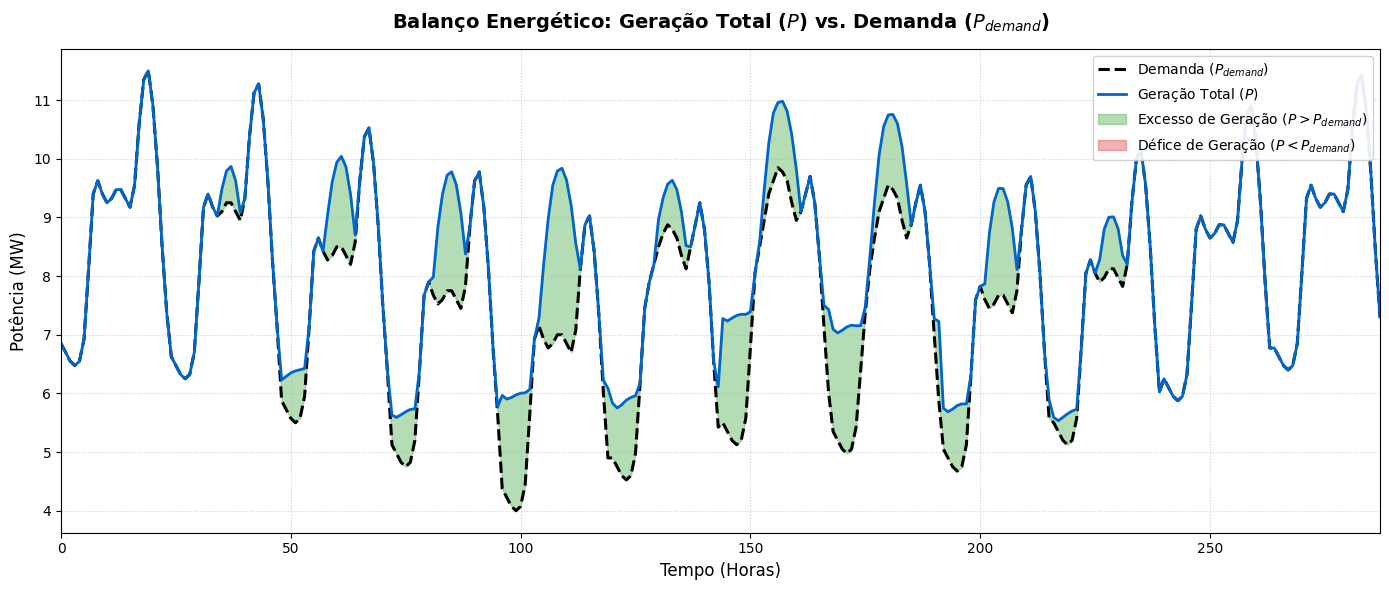

In [33]:
P_thermal = np.maximum(thermal_P_min, P_demand - (solar_power + wind_power + P_hydro)) / 1e6  # Convertendo para MW
P = solar_power + wind_power + P_hydro + P_thermal * 1e6  # Convertendo P_thermal de volta para W para somar com as outras potências

# 1. Ajuste de Unidades (Convertendo Watts para Megawatts para legibilidade)
# Se P e P_demand estiverem em W (devido ao multiplicador 1e6), dividimos por 1e6
P_MW = P / 1e6
P_demand_MW = P_demand / 1e6 

# Eixo temporal (288 horas)
horas = np.arange(len(P_MW))

# 2. Criação da Figura
plt.figure(figsize=(14, 6), dpi=100)

# Curvas Principais
plt.plot(horas, P_demand_MW, label='Demanda ($P_{demand}$)', color='black', linewidth=2.2, linestyle='--')
plt.plot(horas, P_MW, label='Geração Total ($P$)', color='#0066cc', linewidth=2)

# 3. Preenchimento de Excesso vs. Défice
# Área verde: Geração acima da demanda (Sobra de energia / Excesso)
plt.fill_between(horas, P_MW, P_demand_MW, where=(P_MW >= P_demand_MW), 
                 color='#2ca02c', alpha=0.35, interpolate=True, label='Excesso de Geração ($P > P_{demand}$)')

# Área vermelha: Geração abaixo da demanda (Défice a cobrir)
plt.fill_between(horas, P_MW, P_demand_MW, where=(P_MW < P_demand_MW), 
                 color='#d62728', alpha=0.35, interpolate=True, label='Défice de Geração ($P < P_{demand}$)')

# 4. Formatação e Estética
plt.title('Balanço Energético: Geração Total ($P$) vs. Demanda ($P_{demand}$)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tempo (Horas)', fontsize=12)
plt.ylabel('Potência (MW)', fontsize=12)
plt.xlim(0, len(horas) - 1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

In [34]:
#Energia Renovável Anual por Fonte (MWh)
DAYS_IN_MONTH = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
days_per_hour = np.repeat(DAYS_IN_MONTH, 24)

renewables = (solar_power + wind_power + P_hydro) / 1e6  # Convertendo para MW

E_solar_annual = (solar_power /1e6 * days_per_hour).sum()
E_wind_annual = (wind_power /1e6 * days_per_hour).sum()
E_hydro_annual = (P_hydro /1e6 * days_per_hour).sum()
E_renewables_annual = (renewables * days_per_hour).sum()

# 3. Demanda Total Anual (MWh)
E_demand_annual = (P_demand_MW * days_per_hour).sum()

# 4. Energia Térmica Anual (MWh)
E_thermal_B_annual = (P_thermal * days_per_hour).sum()

# Impressão dos Resultados
print(f"Demanda Total Anual: {E_demand_annual:,.2f} MWh")
print(f"--- PRODUÇÃO RENOVÁVEL ---")
print(f"Produção Solar Anual: {E_solar_annual:,.2f} MWh")
print(f"Produção Eólica Anual: {E_wind_annual:,.2f} MWh")
print(f"Produção Hídrica Anual: {E_hydro_annual:,.2f} MWh")
print(f"Produção Renovável Total Anual: {E_renewables_annual:,.2f} MWh")
print(f"--- PRODUÇÃO TÉRMICA ---")
print(f"Energia Térmica Anual (Cenário B): {E_thermal_B_annual:,.2f} MWh")

Demanda Total Anual: 67,976.55 MWh
--- PRODUÇÃO RENOVÁVEL ---
Produção Solar Anual: 10,152.99 MWh
Produção Eólica Anual: 18,660.29 MWh
Produção Hídrica Anual: 4,577.55 MWh
Produção Renovável Total Anual: 33,390.84 MWh
--- PRODUÇÃO TÉRMICA ---
Energia Térmica Anual (Cenário B): 38,901.19 MWh
